# ENGE707 — Facial Feature Classification: From Investigation to Final Pipeline

**Rebuilt, self-contained investigation notebook.** Execute in order. This notebook never loads project-specific model checkpoints, saved probabilities, previous Kaggle submissions, flagged images or old training logs. Results and Grad-CAMs are generated **from models trained in this run**. Pretrained ImageNet/DINOv2 backbones are downloaded from their public official sources as part of transfer learning.

1. Inspect labelled training data and unlabelled test images.
2. Investigate class distribution, image geometry, colour, edge information and augmentation; guard against train/validation leakage.
3. Train reconstructed Scratch CNN V1, Scratch CNN V2 and pretrained ResNet-18 baselines; compare learning curves, confusion matrices and Grad-CAM maps. Test ConvNeXt-Tiny as a further pretrained CNN baseline.
4. Train the final **ConvNeXt-Base + DINOv2-Large (LoRA)** models using RGB input, reflective framing, mild augmentation, geometry adversaries and two-view consistency.
5. Compare errors on a labelled validation subset, ensemble probabilities, predict the unseen test images, and automatically flag possible OOD inputs.

**Honest reproducibility:** the original experiments reported 81.50%, 95.71%, 98.99%, 97.06% and a final 97.53% Kaggle public score. Those are *historical observations*, not predetermined outputs of these fresh training runs. Architecture and training details are simplified here, so scores may differ. The old checkpoints would be required to reproduce their exact weights and Grad-CAMs.

**Full image folders were not provided in this project snapshot, so full training is not executed here.** The notebook has been checked on a small synthetic dataset only.

**Required files:** `train_labels.csv`, `sample_submission.csv`, the complete `train/` image directory and complete `test/` image directory. Image files may be one directory deeper, e.g. `train/train/`. No other old files are required. Ensure enough hardware for final DINOv2-Large training. All generated results go to a **new `results/` directory**, never read back as an input.

## 1. Setup and dataset audit

Run `pip install torch torchvision transformers peft accelerate pandas numpy pillow matplotlib scikit-learn` in your Python environment if dependencies are missing. CUDA is optional for setup and visualisations; training large backbones on CPU is extremely slow. There are **no device-specific tuning switches**. Near the end there is just one boolean for starting the final expensive training.

In [1]:
from pathlib import Path
import random, hashlib, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = Path.cwd()
CLASSES = ['CatEye','CatFace','CatMouth','CatNose','DogEye','DogFace','DogMouth','DogNose']
MEAN, STD = (0.485,0.456,0.406), (0.229,0.224,0.225)
IMAGE_EXT = {'.png','.jpg','.jpeg','.bmp','.webp','.tif','.tiff'}

def index_images(folder):
    files = [p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXT]
    result = {}
    for p in files:
        import re
        m = re.search(r'(\d+)$', p.stem)
        if m:
            key = int(m.group(1))
            if key in result: raise ValueError(f'Duplicate filename image ID: {key}')
            result[key] = p
    return result

assert (ROOT/'train_labels.csv').is_file() and (ROOT/'sample_submission.csv').is_file(), 'Missing required CSV files.'
assert (ROOT/'train').is_dir() and (ROOT/'test').is_dir(), 'Copy both complete image folders into this directory.'
train_files, test_files = index_images(ROOT/'train'), index_images(ROOT/'test')
labels = pd.read_csv(ROOT/'train_labels.csv')
sample = pd.read_csv(ROOT/'sample_submission.csv')
labels['image_id'] = labels.image_id.astype(int)
sample['image_id'] = sample.image_id.astype(int)
assert list(sample.columns) == ['image_id','class'] and set(labels['class']) == set(CLASSES)
assert labels.image_id.is_unique and sample.image_id.is_unique
assert set(labels.image_id) == set(train_files), 'Missing/mismatched training images.'
assert set(sample.image_id) == set(test_files), 'Missing/mismatched test images.'
labels['target'] = labels['class'].map({c:i for i,c in enumerate(CLASSES)})
print('Device:',device,'| train:',len(labels),'| test:',len(sample))
print('The train and test image IDs are separate namespaces; identical ID numbers are allowed.')

Device: cuda | train: 63660 | test: 29443
The train and test image IDs are separate namespaces; identical ID numbers are allowed.


,images
class,
CatEye,13884
CatFace,6942
CatMouth,6942
CatNose,6942
DogEye,11580
DogFace,5790
DogMouth,5790
DogNose,5790


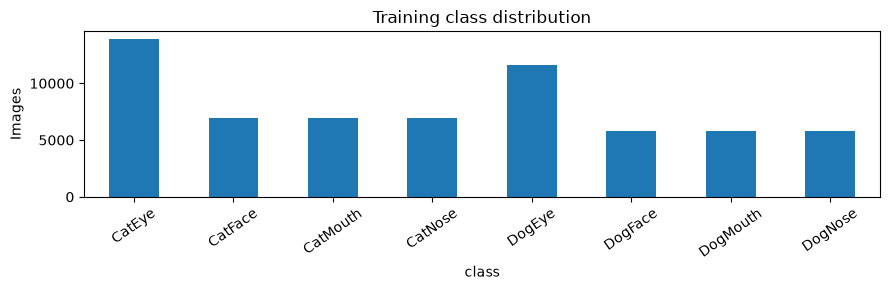

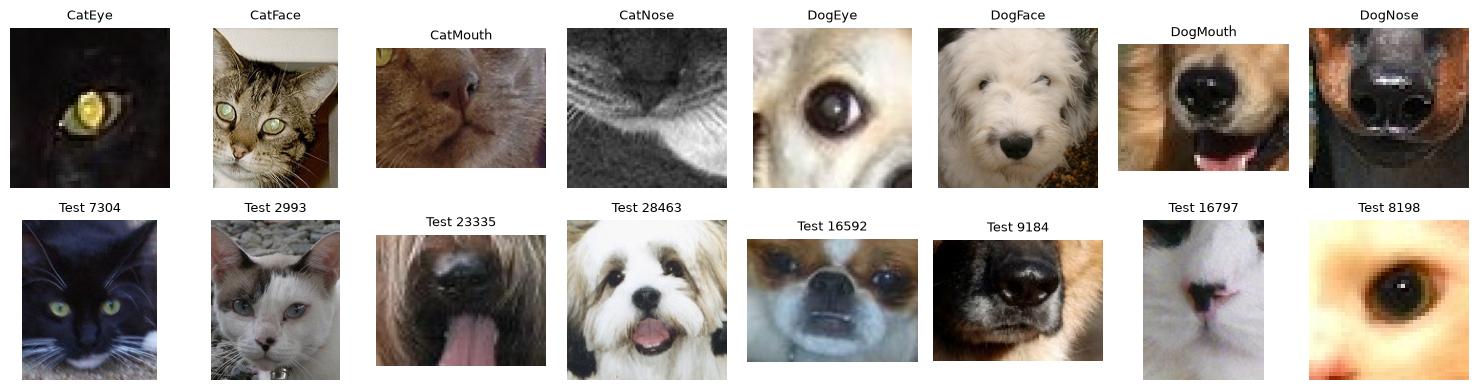

In [2]:
# Class imbalance and sample images — do not infer labels from Kaggle test IDs.
counts = labels['class'].value_counts().reindex(CLASSES)
display(counts.rename('images').to_frame())
counts.plot.bar(title='Training class distribution',ylabel='Images',rot=35,figsize=(9,3)); plt.tight_layout(); plt.show()

fig,axes=plt.subplots(2,8,figsize=(15,4))
for i,c in enumerate(CLASSES):
    r=labels[labels['class']==c].sample(1,random_state=SEED).iloc[0]
    with Image.open(train_files[int(r.image_id)]) as im: axes[0,i].imshow(im.convert('RGB'))
    axes[0,i].set_title(c,fontsize=9)
for i,ident in enumerate(sample.image_id.sample(8,random_state=SEED)):
    with Image.open(test_files[int(ident)]) as im: axes[1,i].imshow(im.convert('RGB'))
    axes[1,i].set_title(f'Test {ident}',fontsize=9)
for ax in axes.flat:ax.axis('off')
plt.tight_layout();plt.show()

### Image dimensions, RGB information and possible shortcuts

Source dimensions and colour characteristics are useful diagnostics, but not evidence of a real anatomical difference. The earlier geometry-only experiment showed that non-anatomical image cues could predict labels.

,width,height,aspect,pixels
class,,,,
CatEye,68.0,68.0,1.00,4624.0
CatFace,182.0,215.0,0.83,39398.0
CatMouth,114.0,80.0,1.42,9120.0
CatNose,68.0,68.0,1.00,4624.0
DogEye,62.0,62.0,1.00,3844.0
DogFace,155.0,155.0,1.00,24025.0
DogMouth,104.0,77.0,1.35,8008.0
DogNose,62.0,62.0,1.00,3844.0


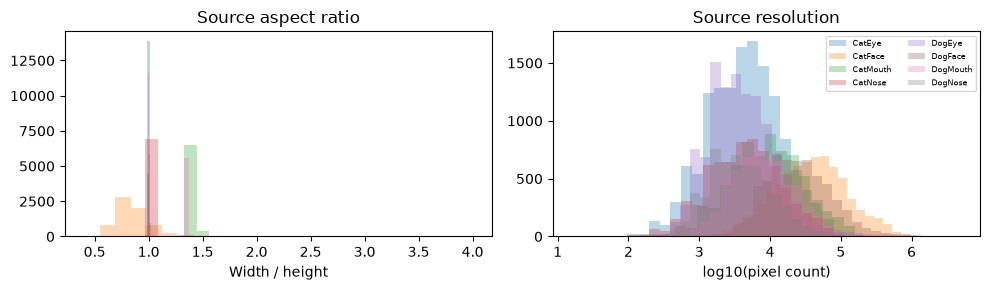

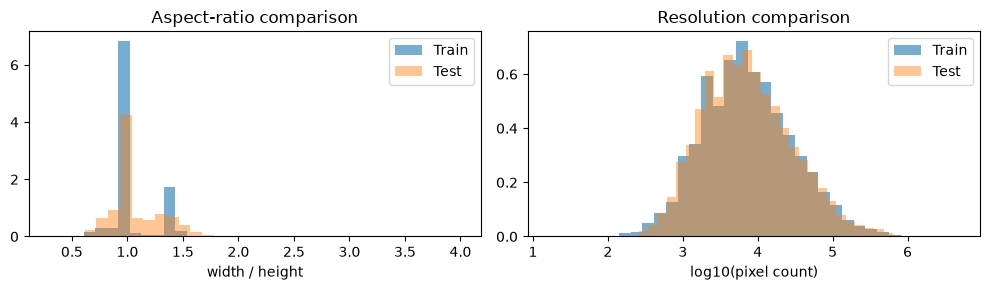

In [3]:
# Read only image headers for dimensions. Full-image decoding is unnecessary here.
rows=[]
for r in labels.itertuples(index=False):
    with Image.open(train_files[int(r.image_id)]) as im: w,h=im.size
    rows.append((int(r.image_id),w,h,w/h,w*h))
geometry=pd.DataFrame(rows,columns=['image_id','width','height','aspect','pixels'])
labels=labels.merge(geometry,on='image_id',validate='one_to_one')
display(labels.groupby('class')[['width','height','aspect','pixels']].median().round(2))

fig,axes=plt.subplots(1,2,figsize=(10,3))
for c in CLASSES:
    subset=labels[labels['class']==c]
    axes[0].hist(subset['aspect'].clip(0,4),bins=25,alpha=.3,label=c)
    axes[1].hist(np.log10(subset['pixels']),bins=25,alpha=.3,label=c)
axes[0].set(title='Source aspect ratio',xlabel='Width / height')
axes[1].set(title='Source resolution',xlabel='log10(pixel count)')
axes[1].legend(fontsize=6,ncol=2)
plt.tight_layout();plt.show()
# Unlabelled test images: compare source resolution to the training distribution.
test_dims=[]
for key,p in test_files.items():
    with Image.open(p) as im:w,h=im.size
    test_dims.append((w/h,w*h))
test_geometry=pd.DataFrame(test_dims,columns=['aspect','pixels'])
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].hist(labels.aspect.clip(0,4),bins=35,alpha=.6,density=True,label='Train')
axes[0].hist(test_geometry.aspect.clip(0,4),bins=35,alpha=.45,density=True,label='Test')
axes[1].hist(np.log10(labels.pixels),bins=35,alpha=.6,density=True,label='Train')
axes[1].hist(np.log10(test_geometry.pixels),bins=35,alpha=.45,density=True,label='Test')
axes[0].set(title='Aspect-ratio comparison',xlabel='width / height')
axes[1].set(title='Resolution comparison',xlabel='log10(pixel count)')
for ax in axes:ax.legend()
plt.tight_layout();plt.show()


,R,G,B,contrast
class,,,,
CatEye,0.489,0.426,0.357,0.194
CatFace,0.519,0.465,0.415,0.242
CatMouth,0.500,0.458,0.429,0.177
CatNose,0.461,0.416,0.376,0.176
DogEye,0.475,0.410,0.365,0.200
DogFace,0.431,0.365,0.311,0.210
DogMouth,0.406,0.367,0.323,0.213
DogNose,0.411,0.363,0.334,0.195


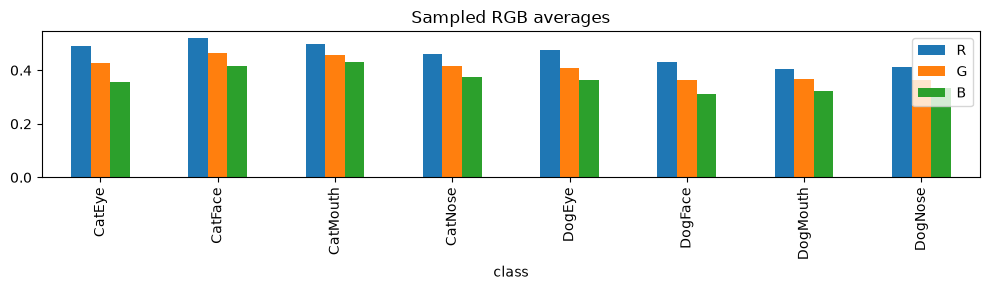

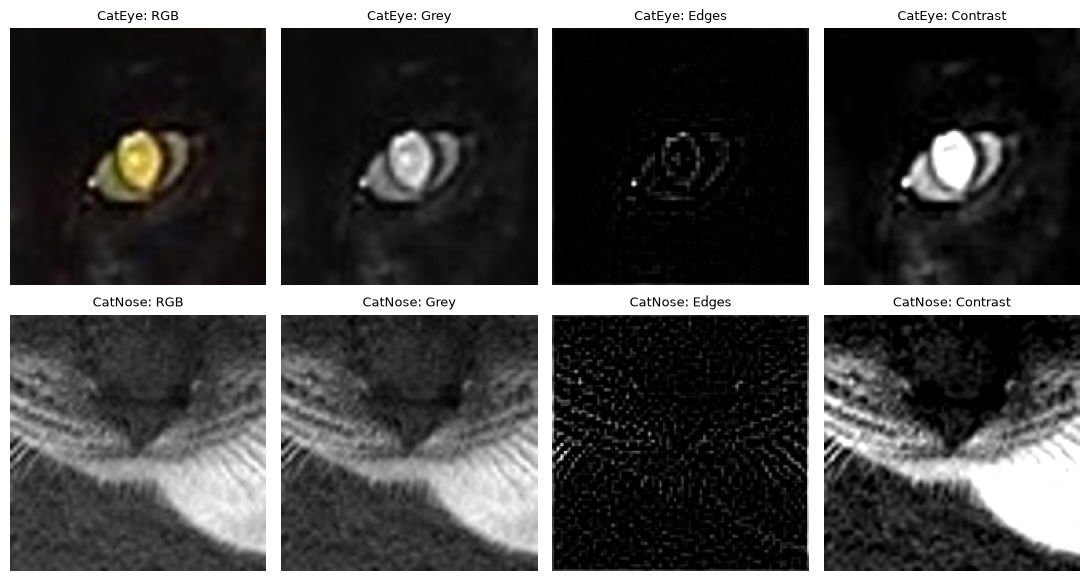

In [4]:
# Simple RGB and edge diagnostics on small, equally sampled training groups.
from PIL import ImageEnhance
probe=labels.groupby('class',group_keys=False).sample(n=24,random_state=SEED)
rgb=[]
for _,r in probe.iterrows():
    with Image.open(train_files[int(r['image_id'])]) as im:
        a=np.asarray(im.convert('RGB').resize((64,64)),dtype=np.float32)/255
    rgb.append((r['class'],*a.mean((0,1)),float(a.std())))
colour=pd.DataFrame(rgb,columns=['class','R','G','B','contrast'])
display(colour.groupby('class')[['R','G','B','contrast']].mean().round(3))
colour.groupby('class')[['R','G','B']].mean().plot.bar(figsize=(10,3),title='Sampled RGB averages');plt.tight_layout();plt.show()

fig,axes=plt.subplots(2,4,figsize=(11,6))
for idx,ax in enumerate(axes.flat):
    c=['CatEye','CatNose'][idx//4]
    r=labels[labels['class']==c].sample(1,random_state=SEED).iloc[0]
    with Image.open(train_files[int(r.image_id)]) as im: image=im.convert('RGB').resize((160,160))
    versions=[image,ImageOps.grayscale(image),ImageOps.grayscale(image).filter(ImageFilter.FIND_EDGES),
              ImageEnhance.Contrast(ImageOps.grayscale(image)).enhance(1.8)]
    v=versions[idx%4]
    ax.imshow(v,cmap='gray' if v.mode=='L' else None)
    ax.set_title(f'{c}: {("RGB","Grey","Edges","Contrast")[idx%4]}',fontsize=9);ax.axis('off')
plt.tight_layout();plt.show()

### Leakage-safe validation split

We identify byte-identical training images by SHA256 hash and use a stratified group split. This prevents exact duplicates from appearing in both training and validation. This is a new split calculated from the images present now, not a recovered historical split. We never use test labels.

In [5]:
labels['sha256']=[hashlib.sha256(train_files[int(i)].read_bytes()).hexdigest() for i in labels.image_id]
assert labels.groupby('sha256')['class'].nunique().max()==1, 'Identical images have conflicting labels.'
tr_idx,va_idx=next(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED).split(
    labels,labels.target,groups=labels.sha256))
train_df=labels.iloc[tr_idx].reset_index(drop=True)
val_df=labels.iloc[va_idx].reset_index(drop=True)
assert set(train_df.sha256).isdisjoint(val_df.sha256)
print('Training:',len(train_df),'Validation:',len(val_df),'Exact duplicate groups:',labels.sha256.duplicated().sum())

Training: 50928 Validation: 12732 Exact duplicate groups: 15


In [6]:
# Geometry-only benchmark: tests whether source-image metadata contains label shortcuts.
cols=['width','height','aspect','pixels']
gmodel=make_pipeline(StandardScaler(),LogisticRegression(max_iter=350))
gmodel.fit(train_df[cols],train_df.target)
g_pred=gmodel.predict(val_df[cols])
print('Geometry-only validation accuracy:',round(accuracy_score(val_df.target,g_pred),4))
print('Interpretation: above-chance results indicate possible dataset shortcuts, not visual recognition.')

Geometry-only validation accuracy: 0.5246
Interpretation: above-chance results indicate possible dataset shortcuts, not visual recognition.


## 2. Preprocessing and augmentation investigation

The initial scratch CNNs trained on ordinary RGB tensors; the later models used ImageNet-style normalisation and aspect-preserving reflective padding. Stretching distorts tight crops, while aggressive augmentation can erase facial details. This section compares the input representations and previews the **actual** mild training augmentations.

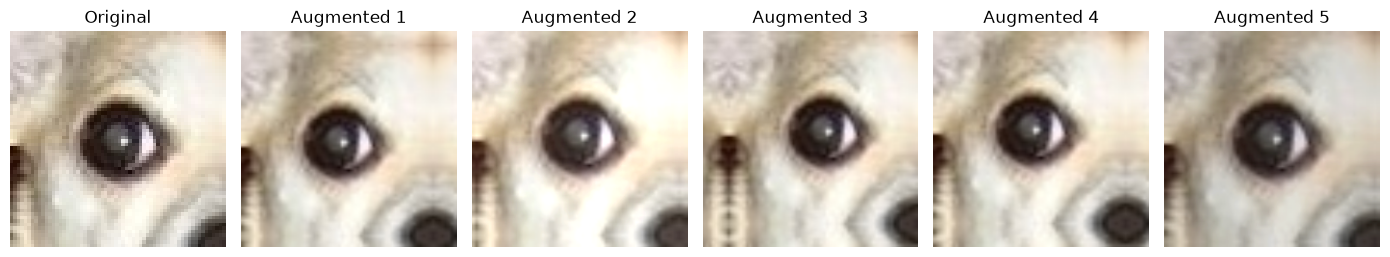

In [7]:
class ReflectSquare:
    def __init__(self,random_position=False):self.random_position=random_position
    def __call__(self,image):
        a=np.asarray(image.convert('RGB'));h,w=a.shape[:2]
        size=round(max(h,w)*random.uniform(1,1.18)) if self.random_position else max(h,w)
        dx,dy=size-w,size-h
        left=random.randint(0,dx) if self.random_position else dx//2
        top=random.randint(0,dy) if self.random_position else dy//2
        return Image.fromarray(np.pad(a,((top,dy-top),(left,dx-left),(0,0)),mode='reflect' if min(h,w)>1 else 'edge'))

def transform(size=224,training=False,pretrained=True,reflect=True):
    ops=[ReflectSquare(training)] if reflect else []
    ops += [T.Resize((size,size)),T.RandomHorizontalFlip(.5)] if training else [T.Resize((size,size))]
    if training:ops += [T.RandomApply([T.ColorJitter(.12,.12,.10,.01)],p=.5),
                       T.RandomApply([T.GaussianBlur(3,sigma=(.1,.8))],p=.1)]
    ops += [T.ToTensor()]
    if pretrained:ops += [T.Normalize(MEAN,STD)]
    return T.Compose(ops)

r=labels[labels['class']=='DogEye'].sample(1,random_state=SEED).iloc[0]
with Image.open(train_files[int(r.image_id)]) as im: original=im.convert('RGB')
fig,axes=plt.subplots(1,6,figsize=(14,3))
axes[0].imshow(original);axes[0].set_title('Original')
for i in range(1,6):
    x=transform(224,True,True)(original)
    x=(x*torch.tensor(STD)[:,None,None]+torch.tensor(MEAN)[:,None,None]).clamp(0,1)
    axes[i].imshow(x.permute(1,2,0));axes[i].set_title(f'Augmented {i}')
for ax in axes:ax.axis('off')
plt.tight_layout();plt.show()

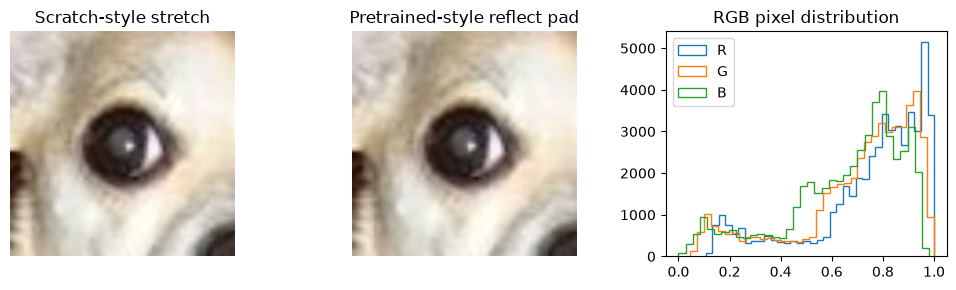

In [8]:
# Same original image under earlier scratch-style versus pretrained-style inputs.
raw=transform(224,False,False,False)(original)
pre=transform(224,False,True,True)(original)
fig,axes=plt.subplots(1,3,figsize=(10,3))
axes[0].imshow(raw.permute(1,2,0));axes[0].set_title('Scratch-style stretch')
axes[1].imshow((pre*torch.tensor(STD)[:,None,None]+torch.tensor(MEAN)[:,None,None]).clamp(0,1).permute(1,2,0))
axes[1].set_title('Pretrained-style reflect pad')
for j,c in enumerate('RGB'):
    axes[2].hist(raw[j].ravel(),bins=35,histtype='step',label=c)
axes[2].set_title('RGB pixel distribution');axes[2].legend()
for ax in axes[:2]:ax.axis('off')
plt.tight_layout();plt.show()

## 3. Reproducing the model investigations

These **reconstructed baseline architectures** train using the newly prepared split: Scratch CNN V1, a deeper Scratch CNN V2, and a pretrained ResNet-18 with shared species/feature heads. The original checkpoint weights are *not* reused. We examine training curves, confusion matrices and Grad-CAM maps, then make a short ConvNeXt-Tiny comparison. The lower-level models use `Cat/Dog` and `Eye/Face/Mouth/Nose` labels, combined into eight-class probabilities for evaluation.

**Historic project results (for context only; NOT generated by this notebook):**

| Previous experiment | Recorded validation | Public Kaggle |
|---|---:|---:|
| Scratch CNN V1 | 81.50% | — |
| Scratch CNN V2 | 95.71% | — |
| ResNet-18 | 98.99% | — |
| ConvNeXt-Tiny with flip TTA | ~99.60% | 97.06% |
| DINOv2-Large with multiscale TTA | ~99.67% | 96.41% |
| Tiny + DINO ensemble | — | 97.35% |
| **ConvNeXt-Base + DINO ensemble** | **99.827% (held-out audit)** | **97.53%** |

The audit score is not directly comparable to full-validation scores. Training new baseline models below illustrates the progression but won't necessarily repeat these scores.


In [9]:
class Images(Dataset):
    def __init__(self,table,size=224,training=False,pretrained=True,reflect=True):
        self.table=table.reset_index(drop=True)
        self.tf=transform(size,training,pretrained,reflect)
    def __len__(self):return len(self.table)
    def __getitem__(self,i):
        row=self.table.iloc[i]
        with Image.open(train_files[int(row.image_id)]) as im:x=self.tf(im.convert('RGB'))
        y=int(row.target)
        return x,y

def loaders(size=224,pretrained=True,reflect=True,batch=32):
    train=DataLoader(Images(train_df,size,True,pretrained,reflect),batch_size=batch,shuffle=True)
    val=DataLoader(Images(val_df,size,False,pretrained,reflect),batch_size=batch)
    return train,val

class JointClassifier(nn.Module):
    def __init__(self,encoder,dim):
        super().__init__()
        self.encoder=encoder
        self.species=nn.Linear(dim,2)
        self.part=nn.Linear(dim,4)
    def forward(self,x):
        z=self.encoder(x)
        if z.ndim==4:z=F.adaptive_avg_pool2d(z,1).flatten(1)
        return self.species(z),self.part(z)

def scratch_v1():
    enc=nn.Sequential(nn.Conv2d(3,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                      nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                      nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
    return JointClassifier(enc,64), enc[6]

def scratch_v2():
    seq=[];sizes=[3,32,64,128,256]
    for a,b in zip(sizes[:-1],sizes[1:]):
        seq += [nn.Conv2d(a,b,3,padding=1),nn.BatchNorm2d(b),nn.ReLU(),nn.MaxPool2d(2)]
    enc=nn.Sequential(*seq)
    return JointClassifier(enc,256),enc[-4]

def resnet18():
    enc=models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    enc.fc=nn.Identity()
    return JointClassifier(enc,512),enc.layer4[-1]

def eight_probs(a,b):
    return (a.softmax(1)[:,:,None]*b.softmax(1)[:,None,:]).flatten(1)

In [10]:
# Shared compact training loop; models are re-created and trained here, never restored.
def fit_joint(net,train,val,epochs=4,lr=.001):
    net=net.to(device)
    opt=torch.optim.AdamW(net.parameters(),lr=lr)
    logs=[]
    for epoch in range(epochs):
        net.train();total=0
        for x,y in train:
            x,y=x.to(device),y.to(device)
            a,b=net(x)
            loss=F.cross_entropy(a,y//4)+F.cross_entropy(b,y%4)
            opt.zero_grad();loss.backward();opt.step();total+=loss.item()*len(y)
        net.eval();truth=[];pred=[]
        with torch.no_grad():
            for x,y in val:
                a,b=net(x.to(device));truth.extend(y.tolist());pred.extend(eight_probs(a,b).argmax(1).cpu().tolist())
        acc=accuracy_score(truth,pred)
        logs.append({'epoch':epoch+1,'train_loss':total/len(train.dataset),'val_accuracy':acc})
        print(f'Epoch {epoch+1:02d} | loss {logs[-1]["train_loss"]:.4f} | accuracy {acc:.3%}')
    return net,pd.DataFrame(logs),np.array(truth),np.array(pred)

experiments={}
for name,build,pretrained,reflect,epochs,lr in [
    ('Scratch V1',scratch_v1,False,False,5,.001),
    ('Scratch V2',scratch_v2,False,True,5,.001),
    ('ResNet-18',resnet18,True,True,4,.0001)]:
    print('\nTraining',name)
    net,layer=build()
    training,validation=loaders(224,pretrained,reflect,32)
    net,history,truth,pred=fit_joint(net,training,validation,epochs,lr)
    experiments[name]={'model':net.cpu(),'layer':layer,'history':history,'true':truth,'pred':pred}


Training Scratch V1
Epoch 01 | loss 1.9047 | accuracy 27.992%
Epoch 02 | loss 1.7188 | accuracy 37.080%
Epoch 03 | loss 1.5393 | accuracy 43.363%
Epoch 04 | loss 1.4160 | accuracy 50.660%
Epoch 05 | loss 1.3159 | accuracy 53.472%

Training Scratch V2
Epoch 01 | loss 1.4052 | accuracy 53.707%
Epoch 02 | loss 0.9941 | accuracy 61.459%
Epoch 03 | loss 0.8024 | accuracy 70.138%
Epoch 04 | loss 0.6922 | accuracy 71.426%
Epoch 05 | loss 0.6159 | accuracy 74.851%

Training ResNet-18
Epoch 01 | loss 0.1155 | accuracy 97.691%
Epoch 02 | loss 0.0420 | accuracy 98.492%
Epoch 03 | loss 0.0328 | accuracy 98.233%
Epoch 04 | loss 0.0255 | accuracy 98.107%


Newly measured results:


,accuracy,macro_f1
Scratch V1,0.5347,0.5207
Scratch V2,0.7485,0.7346
ResNet-18,0.9811,0.9799


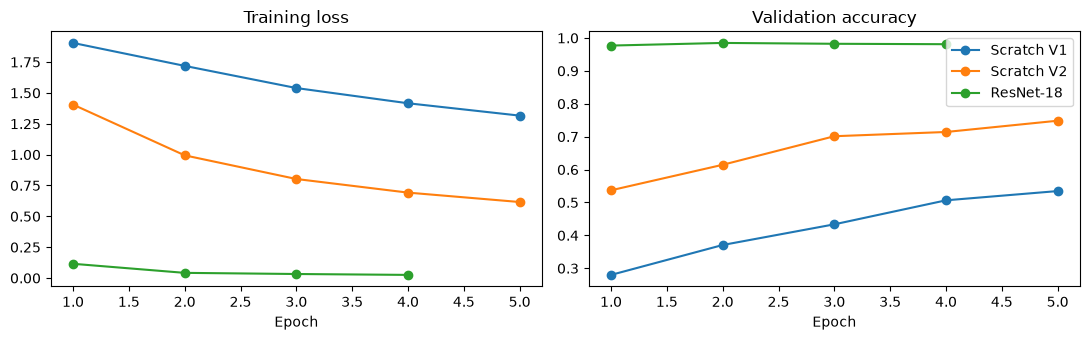

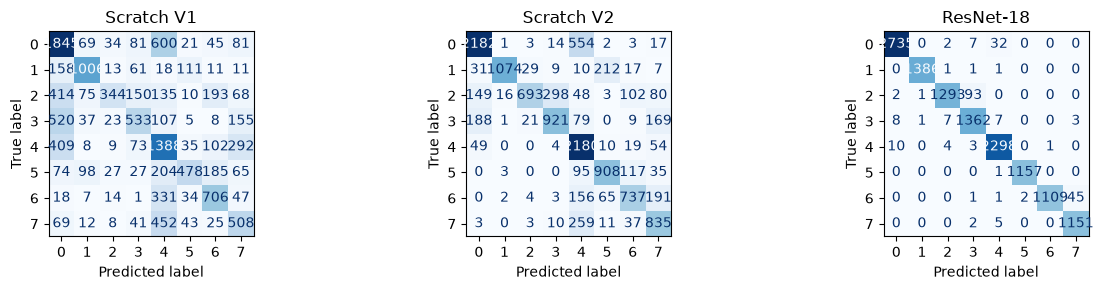

In [11]:
# Actual results from THIS run, not the archived 81.50 / 95.71 / 98.99 scores.
results=pd.DataFrame({name:{'accuracy':accuracy_score(v['true'],v['pred']),
                            'macro_f1':f1_score(v['true'],v['pred'],average='macro')}
                      for name,v in experiments.items()}).T
print('Newly measured results:');display(results.round(4))
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for name,v in experiments.items():
    h=v['history'];axes[0].plot(h.epoch,h.train_loss,marker='o',label=name)
    axes[1].plot(h.epoch,h.val_accuracy,marker='o',label=name)
axes[0].set(title='Training loss',xlabel='Epoch');axes[1].set(title='Validation accuracy',xlabel='Epoch')
axes[1].legend();plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(13,3))
for ax,(name,v) in zip(axes,experiments.items()):
    ConfusionMatrixDisplay.from_predictions(v['true'],v['pred'],ax=ax,colorbar=False,
                                        cmap='Blues',values_format='d')
    ax.set_title(name)
plt.tight_layout();plt.show()

### Grad-CAM: where do Scratch V1, Scratch V2 and ResNet-18 look?

Use one **DogEye** example and backpropagate the `Dog` and `Eye` logits separately. Each map is generated from a trained network in this notebook, unlike the previous cleaned notebook which depended on archived model objects. Lower spatial resolution in a heatmap is a property of the model's feature layer, not proof of inferior accuracy.

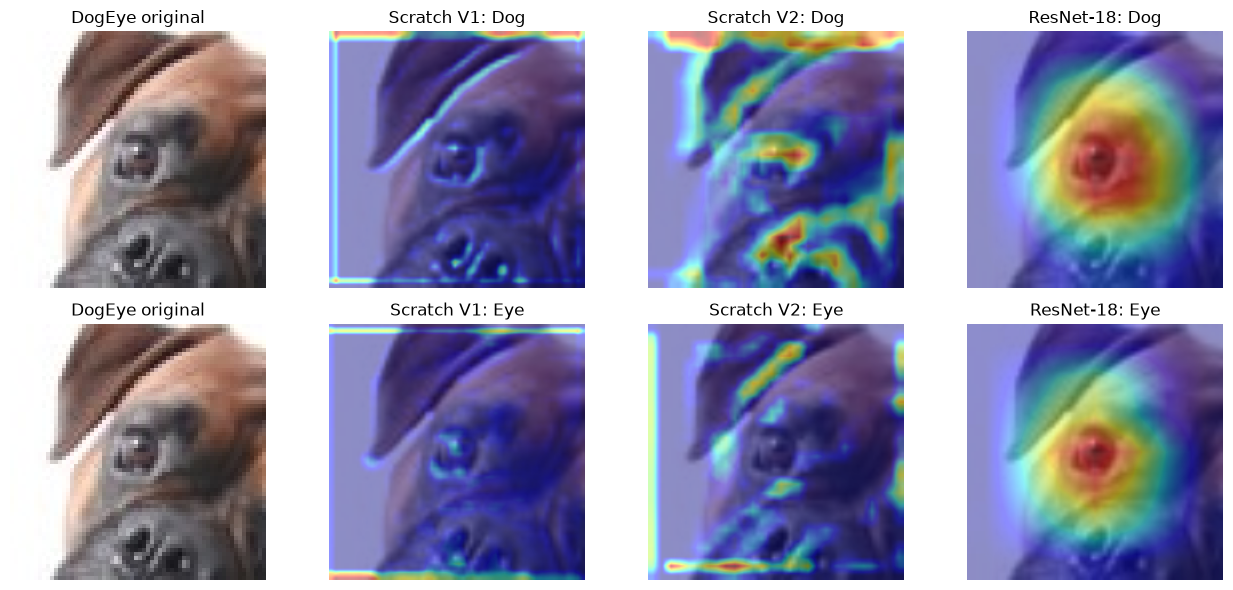

In [12]:
# Grad-CAM from the actual trained baseline models (not generic image colouring).
def gradcam(net,layer,x,head,target):
    saved={}
    def hook(_layer,_args,out):
        saved['activation']=out
        out.retain_grad()
    handle=layer.register_forward_hook(hook)
    try:
        net.eval();net.zero_grad(set_to_none=True)
        s,p=net(x)
        (s if head=='species' else p)[0,target].backward()
        a=saved['activation'];weight=a.grad.mean((2,3),keepdim=True)
        heat=F.relu((weight*a).sum(1,keepdim=True))
        heat=F.interpolate(heat,size=x.shape[-2:],mode='bilinear',align_corners=False)[0,0]
        heat=heat-heat.min()
        return (heat/(heat.max()+1e-8)).detach().cpu().numpy()
    finally:handle.remove()

item=val_df[val_df['class']=='DogEye'].iloc[0]
with Image.open(train_files[int(item.image_id)]) as im:original=im.convert('RGB')
fig,axes=plt.subplots(2,4,figsize=(13,6))
for row,(head,target) in enumerate([('species',1),('part',0)]):
    axes[row,0].imshow(original);axes[row,0].set_title('DogEye original')
    for col,(name,v) in enumerate(experiments.items(),1):
        inputs=transform(224,False,name=='ResNet-18',name!='Scratch V1')(original)
        heat=gradcam(v['model'].to(device),v['layer'],inputs.unsqueeze(0).to(device),head,target)
        v['model'].cpu()
        axes[row,col].imshow(inputs.permute(1,2,0)*torch.tensor(STD)+torch.tensor(MEAN)
                             if name=='ResNet-18' else inputs.permute(1,2,0))
        axes[row,col].imshow(heat,cmap='jet',alpha=.45)
        axes[row,col].set_title(f'{name}: {("Dog","Eye")[row]}')
    for ax in axes[row]:ax.axis('off')
plt.tight_layout();plt.show()

### Transfer-learning extension: ConvNeXt-Tiny

ResNet-18 establishes the usefulness of pretrained visual features. The earlier ConvNeXt-Tiny experiment provided another gain on Kaggle. This short fresh trial is illustrative only; it cannot reproduce the original 97.06% without the old complete training conditions.

In [13]:
# A short transfer-learning comparison; trained anew, not loaded from old project files.
tiny=models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
tiny.classifier[-1]=nn.Linear(tiny.classifier[-1].in_features,8)
tiny=tiny.to(device)
opt=torch.optim.AdamW(tiny.parameters(),lr=2e-5)
train_loader,val_loader=loaders(224,True,True,batch=16)
tiny_history=[]
for epoch in range(3):
    tiny.train()
    for x,y in train_loader:
        x,y=x.to(device),y.to(device)
        loss=F.cross_entropy(tiny(x),y)
        opt.zero_grad();loss.backward();opt.step()
    tiny.eval();truth=[];pred=[]
    with torch.no_grad():
        for x,y in val_loader:
            truth.extend(y.tolist());pred.extend(tiny(x.to(device)).argmax(1).cpu().tolist())
    tiny_history.append(accuracy_score(truth,pred))
    print('ConvNeXt-Tiny epoch',epoch+1,'validation:',round(tiny_history[-1],4))
tiny=tiny.cpu()  # Preserve the recorded metrics, release accelerator for the final models.


ConvNeXt-Tiny epoch 1 validation: 0.9907
ConvNeXt-Tiny epoch 2 validation: 0.9922
ConvNeXt-Tiny epoch 3 validation: 0.9848


## 4. Final training — ConvNeXt-Base and DINOv2-Large

Only **one user switch** starts this expensive section. The two models train with **new** weights initialised from public pretrained backbones, using the newly calculated split. This reconstructs the final ideas rather than relying on archived experiments. It does **not guarantee** reproduction of the original 97.53% public score.

- ConvNeXt-Base: full fine-tuning with geometry-adversarial auxiliary heads and two-view consistency.
- DINOv2-Large: frozen pretrained backbone with rank-8 LoRA adapters, a trainable classifier/geometry heads, and the same two-view principle.
- Validation selects an ensemble weight; original project selected 50/50. CNN flip TTA uses 256px; DINO test inference uses 336/392px flip TTA.

DINOv2-Large requires `transformers`, `peft` and sufficiently capable compute; enabling training may take many hours. No custom cache, resume mechanism or computer-specific paths are used.

In [14]:
# The ONLY run switch in this notebook. Models are trained from newly initialised heads/LoRA.
RUN_FINAL_TRAINING = False

# Fixed experiment design, not an array of tuning switches.
CNN_EPOCHS, DINO_EPOCHS = 5, 5
CNN_SIZE, DINO_SIZE = 256, 336

# Geometry targets are derived from training data only.
size_cuts=np.quantile(np.log(train_df.pixels),[.25,.50,.75])
aspect_cuts=np.quantile(np.log(train_df.aspect),[.25,.50,.75])
for table in (train_df,val_df):
    table['size_bin']=np.searchsorted(size_cuts,np.log(table.pixels))
    table['aspect_bin']=np.searchsorted(aspect_cuts,np.log(table.aspect))

class TwoViews(Dataset):
    def __init__(self,table,size,training=True):
        self.table=table.reset_index(drop=True)
        self.tf=transform(size,training,True,True)
    def __len__(self):return len(self.table)
    def __getitem__(self,i):
        r=self.table.iloc[i]
        with Image.open(train_files[int(r.image_id)]) as im:
            a=self.tf(im.convert('RGB'));b=self.tf(im.convert('RGB'))
        return a,b,int(r.target),int(r.size_bin),int(r.aspect_bin)

class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx,x,scale):ctx.scale=scale;return x.view_as(x)
    @staticmethod
    def backward(ctx,grad):return -ctx.scale*grad,None

class ConvNeXtFinal(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone=models.convnext_base(weights=models.ConvNeXt_Base_Weights.DEFAULT)
        dim=self.backbone.classifier[-1].in_features
        self.backbone.classifier[-1]=nn.Identity()
        self.head=nn.Linear(dim,8)
        self.size_head=nn.Linear(dim,4)
        self.aspect_head=nn.Linear(dim,4)
    def forward(self,x,grl=0):
        f=self.backbone(x).float()
        z=GRL.apply(f,grl)
        return self.head(f),f,self.size_head(z),self.aspect_head(z)

In [15]:
# DINOv2 LoRA uses fresh adapters attached to the publicly pretrained ViT-L/14.
# This function imports the optional libraries only when final training is enabled.
def make_dino():
    from transformers import AutoModel
    from peft import LoraConfig, get_peft_model
    backbone=AutoModel.from_pretrained('facebook/dinov2-large')
    backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
    adapter=LoraConfig(r=8,lora_alpha=16,lora_dropout=.05,
                       target_modules=['query','key','value','dense','fc1','fc2'])
    backbone=get_peft_model(backbone,adapter)
    class DINOFinal(nn.Module):
        def __init__(self,backbone):
            super().__init__()
            self.backbone=backbone
            self.head=nn.Linear(2048,8)
            self.size_head=nn.Linear(2048,4)
            self.aspect_head=nn.Linear(2048,4)
        def forward(self,x,grl=0):
            a=self.backbone(pixel_values=x).last_hidden_state
            f=torch.cat([a[:,0],a[:,1:].mean(1)],dim=1).float()
            z=GRL.apply(f,grl)
            return self.head(f),f,self.size_head(z),self.aspect_head(z)
    net=DINOFinal(backbone).to(device)
    n=sum(p.numel() for p in net.parameters() if p.requires_grad)
    print(f'DINOv2 trainable parameters: {n:,}')
    return net

In [16]:
# One training/evaluation routine for both final architectures.
def final_train(net,size,epochs,batch=4):
    training=DataLoader(TwoViews(train_df,size),batch_size=batch,shuffle=True)
    evaluation=DataLoader(Images(val_df,size,False,True,True),batch_size=batch)
    opt=torch.optim.AdamW([p for p in net.parameters() if p.requires_grad],lr=2e-5,weight_decay=.01)
    scaler=torch.amp.GradScaler('cuda',enabled=device.type=='cuda')
    history=[];best_score=-1;best_state=None
    for epoch in range(epochs):
        net.train();total=0
        for a,b,y,sz,ar in training:
            a,b,y,sz,ar=(t.to(device) for t in (a,b,y,sz,ar))
            net.eval()
            with torch.no_grad(),torch.autocast(device.type,enabled=device.type=='cuda'):
                teacher=net(b)[0].float().softmax(1).detach()
            net.train()
            with torch.autocast(device.type,enabled=device.type=='cuda'):
                logits,_,slog,alog=net(a,grl=.12)
                ce=F.cross_entropy(logits.float(),y)
                aux=.5*(F.cross_entropy(slog.float(),sz)+F.cross_entropy(alog.float(),ar))
                consistency=F.kl_div(F.log_softmax(logits.float(),1),teacher,reduction='batchmean')
                loss=ce+.2*aux+.2*consistency
            opt.zero_grad();scaler.scale(loss).backward();scaler.step(opt);scaler.update()
            total+=float(ce.detach())*len(y)
        net.eval();truth=[];pred=[]
        with torch.no_grad():
            for x,y in evaluation:
                truth.extend(y.tolist());pred.extend(net(x.to(device))[0].argmax(1).cpu().tolist())
        score=accuracy_score(truth,pred)
        history.append((epoch+1,total/len(train_df),score))
        print(f'Epoch {epoch+1}: CE {history[-1][1]:.4f}, val accuracy {score:.4%}')
        if score>best_score:
            best_score=score
            best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
    net.load_state_dict(best_state)
    return net,pd.DataFrame(history,columns=['epoch','train_ce','val_accuracy'])

if RUN_FINAL_TRAINING:
    cnn=ConvNeXtFinal().to(device)
    cnn,cnn_history=final_train(cnn,CNN_SIZE,CNN_EPOCHS,batch=8)
    cnn=cnn.cpu()
    dino=make_dino()
    dino,dino_history=final_train(dino,DINO_SIZE,DINO_EPOCHS,batch=2)
    dino=dino.cpu()
    (ROOT/'results').mkdir(exist_ok=True)
    torch.save(cnn.state_dict(),ROOT/'results'/'convnext_base_new.pt')
    dino.backbone.save_pretrained(ROOT/'results'/'dinov2_new_adapter')
    torch.save({k:head.state_dict() for k,head in [('head',dino.head),
               ('size_head',dino.size_head),('aspect_head',dino.aspect_head)]},
               ROOT/'results'/'dinov2_new_heads.pt')
    print('Newly trained model weights saved in results/ (never loaded from old experiments).')
else:
    print('Final training disabled. Set RUN_FINAL_TRAINING=True and rerun this cell to train both models.')

Final training disabled. Set RUN_FINAL_TRAINING=True and rerun this cell to train both models.


In [17]:
# Final training progress (only populated by a fresh final training run).
if RUN_FINAL_TRAINING:
    fig,axes=plt.subplots(1,2,figsize=(10,3))
    for name,h in [('ConvNeXt-Base',cnn_history),('DINOv2-Large',dino_history)]:
        axes[0].plot(h.epoch,h.train_ce,marker='o',label=name)
        axes[1].plot(h.epoch,h.val_accuracy,marker='o',label=name)
    axes[0].set(title='Cross-entropy',xlabel='Epoch')
    axes[1].set(title='Validation accuracy',xlabel='Epoch')
    axes[1].legend();plt.tight_layout();plt.show()


## 5. Validation: compare final models and justify the ensemble

After final training, generate **new** validation probabilities and evaluate each model on the *same* images. Hold out half of validation as a final audit, using the other half only to select ensemble weights. This makes error-overlap measurable without historical submission comparisons.

In [18]:
class InferenceImages(Dataset):
    def __init__(self,paths,ids,size):
        self.paths,self.ids,self.tf=paths,list(map(int,ids)),transform(size,False,True,True)
    def __len__(self):return len(self.ids)
    def __getitem__(self,i):
        key=self.ids[i]
        with Image.open(self.paths[key]) as im:x=self.tf(im.convert('RGB'))
        return x,key

@torch.no_grad()
def predict_model(net,paths,ids,size,flip=True,features=False):
    net=net.to(device).eval()
    data=DataLoader(InferenceImages(paths,ids,size),batch_size=8 if size<=256 else 2)
    probabilities=[];embeddings=[];observed=[]
    for x,keys in data:
        x=x.to(device)
        a,f,_,_=net(x)
        p=a.softmax(1)
        if flip:
            b,g,_,_=net(torch.flip(x,[-1]))
            p=(p+b.softmax(1))/2
            f=(f+g)/2
        probabilities.append(p.cpu().numpy())
        if features:embeddings.append(f.cpu().numpy())
        observed.extend(keys.tolist())
    net.cpu()
    assert observed==list(map(int,ids))
    return np.concatenate(probabilities),np.concatenate(embeddings) if features else None

if RUN_FINAL_TRAINING:
    val_ids=val_df.image_id.to_numpy()
    val_paths={int(i):train_files[int(i)] for i in val_ids}
    p_cnn,f_val=predict_model(cnn,val_paths,val_ids,256,features=True)
    p_dino,_=predict_model(dino,val_paths,val_ids,336)
    y=val_df.target.to_numpy()
    cal,audit=train_test_split(np.arange(len(y)),test_size=.5,random_state=SEED,stratify=y)
    trials=[]
    for weight in np.arange(0,1.01,.05):
        mixture=weight*p_cnn+(1-weight)*p_dino
        trials.append((weight,accuracy_score(y[cal],mixture[cal].argmax(1))))
    selection=pd.DataFrame(trials,columns=['CNN weight','Calibration accuracy'])
    display(selection.sort_values('Calibration accuracy',ascending=False).head())
    weight=float(selection.loc[selection['Calibration accuracy'].idxmax(),'CNN weight'])
    p_ens=weight*p_cnn+(1-weight)*p_dino
    errors=pd.DataFrame({'CNN':p_cnn[audit].argmax(1)!=y[audit],
                         'DINOv2':p_dino[audit].argmax(1)!=y[audit],
                         'Ensemble':p_ens[audit].argmax(1)!=y[audit]})
    summary=pd.DataFrame([
        {'Model':name,'Accuracy':accuracy_score(y[audit],probs[audit].argmax(1)),
         'Macro F1':f1_score(y[audit],probs[audit].argmax(1),average='macro')}
        for name,probs in [('ConvNeXt-Base',p_cnn),('DINOv2-Large',p_dino),('Ensemble',p_ens)]
    ]).set_index('Model')
    display(summary.round(4))
    print('Held-out audit error counts:',errors.sum().to_dict())
    print('Unique CNN errors:',int((errors.CNN & ~errors.DINOv2).sum()),
          '| unique DINO errors:',int((errors.DINOv2 & ~errors.CNN).sum()))
    errors.sum().plot.bar(title='Held-out validation errors',rot=0,ylabel='Errors');plt.tight_layout();plt.show()
else:
    print('This comparison requires fresh trained final models. No old probability files will be loaded.')

This comparison requires fresh trained final models. No old probability files will be loaded.


## 6. Test predictions and automatic OOD flags

A trained classifier must always choose one of the eight Kaggle classes, even for unrecognisable inputs. Flag unusual images **while predicting** using model confidence, entropy, model disagreement and ConvNeXt feature novelty against training-only class centroids. The OOD risk threshold is based only on labelled validation distribution (95th percentile). An OOD flag is a *screening heuristic*, not a verified ground-truth label, and it never replaces the Kaggle prediction. No prior Kaggle submission comparisons or manually flagged test lists are involved.

In [19]:
# Compute one CNN feature centroid per class from training-only examples.
def normalise_rows(a):return a/(np.linalg.norm(a,axis=1,keepdims=True)+1e-12)

def novelty(features,centres):return 1-(normalise_rows(features)@centres.T).max(1)

def entropy(p):
    p=np.clip(p,1e-12,1)
    return -(p*np.log(p)).sum(1)/np.log(p.shape[1])

def disagreement(a,b):
    a,b=np.clip(a,1e-12,1),np.clip(b,1e-12,1)
    m=(a+b)/2
    return .5*((a*np.log(a/m)).sum(1)+(b*np.log(b/m)).sum(1))/np.log(2)

def percentile(x,reference):
    s=np.sort(reference)
    return np.searchsorted(s,x,side='right')/len(s)

def risk_score(p,pc,pd,f,centres,ref):
    n=novelty(f,centres); h=entropy(p); d=disagreement(pc,pd); low=1-p.max(1)
    return (.35*percentile(n,ref[0])+.25*percentile(h,ref[1])+
            .20*percentile(d,ref[2])+.20*percentile(low,ref[3]))

if RUN_FINAL_TRAINING:
    refs=train_df.groupby('target',group_keys=False).sample(n=128,random_state=SEED)
    ref_ids=refs.image_id.to_numpy()
    _,ref_feat=predict_model(cnn,train_files,ref_ids,256,features=True)
    ref_feat=normalise_rows(ref_feat)
    centres=np.stack([ref_feat[refs.target.to_numpy()==k].mean(0) for k in range(8)])
    centres=normalise_rows(centres)
    ref=(novelty(f_val,centres),entropy(p_ens),disagreement(p_cnn,p_dino),1-p_ens.max(1))
    val_risk=risk_score(p_ens,p_cnn,p_dino,f_val,centres,ref)
    threshold=np.quantile(val_risk,.95)

    ids=sample.image_id.to_numpy()
    pc,ft=predict_model(cnn,test_files,ids,256,features=True)
    pd336,_=predict_model(dino,test_files,ids,336)
    pd392,_=predict_model(dino,test_files,ids,392)
    pdino=.75*pd336+.25*pd392
    ptest=weight*pc+(1-weight)*pdino
    scores=risk_score(ptest,pc,pdino,ft,centres,ref)
    predictions=pd.DataFrame({'image_id':ids,'class':np.array(CLASSES)[ptest.argmax(1)]})
    flags=pd.DataFrame({'image_id':ids,'class':predictions['class'],
                        'confidence':ptest.max(1),'entropy':entropy(ptest),
                        'disagreement':disagreement(pc,pdino),
                        'novelty':novelty(ft,centres),'risk_score':scores,
                        'ood_flag':scores>=threshold})
    (ROOT/'results').mkdir(exist_ok=True)
    predictions.to_csv(ROOT/'results'/'submission_new_run.csv',index=False)
    flags.to_csv(ROOT/'results'/'test_ood_flags.csv',index=False)
    print('New submission:',len(predictions),'images | OOD flags:',int(flags.ood_flag.sum()))
    display(flags.sort_values('risk_score',ascending=False).head(12))
else:
    print('No final models trained: test inference and OOD skipped without reading old model files.')

No final models trained: test inference and OOD skipped without reading old model files.


## 7. Interpretation and reporting

Write up the new experiment from the notebook outputs, separating **historic observations** from freshly generated results:

- **Dataset investigation:** class balance, variability in resolution/colour, shortcut potential, and why exact-hash group separation matters.
- **Baseline evidence:** actual learning curves and Grad-CAM maps from the two scratch CNNs and ResNet-18. Changes in maps alone cannot prove a superior model.
- **Augmentation:** compare raw/stretch/reflective images and same-image training views. Mild jitter simulates imperfect images but must preserve small facial details.
- **Final pipeline:** ConvNeXt-Base + LoRA-adapted DINOv2-Large. Show per-model validation results and the held-out ensemble error reduction, or explain when new results differ.
- **OOD:** test-time novelty/uncertainty screening is separate from eight-class Kaggle prediction; threshold choice is heuristic and OOD accuracy is not known without verified OOD labels.
- **Reproducibility:** official pretrained weights are permitted starting points; **no project-specific past checkpoints, predictions, split or label-review files are loaded**.